# Exploratory Data Analysis

## Objective

Turn the verified structure from Phase 1 into business insight. Phase 1 established *what the
data is*; this notebook asks *what the data says*.

Five themes, each answering a set of business questions:

1. **Revenue and seasonality** — how revenue evolves, what drives the average order value, when
   customers buy.
2. **Category and seller performance** — where revenue concentrates, and how dependent the
   marketplace is on a few sellers.
3. **Geography** — how demand and supply are distributed across Brazil, and how much of it
   crosses state lines.
4. **Delivery performance** — how long delivery takes, how often it misses the estimate, and
   where it fails.
5. **Customer experience** — what satisfaction looks like and how strongly it tracks delivery.

## Decisions carried in from Phase 1

| Decision | Choice | Why |
|---|---|---|
| Late-delivery definition | **Strict**: `delivered > estimated` | Matches the documented ML target. The end-of-day variant is noted once as a sensitivity check, never used for headline numbers |
| Review analysis | **Score only** | Text is a biased 41.3% subpopulation (mean 3.67 with text vs 4.38 without); NLP is out of scope here |
| Derived artefacts | **None written** | Phase 3 owns the cleaning pipeline and the order-level dataset |

## Data-quality constraints respected throughout

- `order_reviews` is not 1:1 with orders — deduplicated to the latest review per order before
  any join.
- `order_items` and `order_payments` are aggregated **separately** to order grain, then joined.
  The row count is asserted unchanged after every join.
- 610 products (1.85%) have no category — bucketed as `unknown`, with the denominator stated.
- 2 categories are missing from the translation table — the Portuguese name is used as fallback.
- 2016 and Sep–Oct 2018 are too sparse for trend reading — time series start at 2017-01 and the
  sparse tails are annotated rather than silently plotted.
- `customer_id` is order-scoped; repeat-purchase analysis uses `customer_unique_id`.

## Scope

This notebook **describes** the business. It does not build model features, does not clean data
for production, and does not write files. Every number is computed from the raw CSVs in `data/`,
which are read-only.

## 0. Setup

Project root is resolved by walking upwards from the notebook's own location until the marker
files `data/` and `pyproject.toml` are found, so the notebook runs identically from any working
directory. The same nine CSVs are loaded once and reused.

In [1]:
from __future__ import annotations

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")


def notebook_dir() -> Path:
    try:
        return Path(__file__).resolve().parent
    except NameError:
        return Path.cwd().resolve()


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() and (candidate / "pyproject.toml").is_file():
            return candidate
    raise RuntimeError(f"Could not locate project root (data/ + pyproject.toml) from {start}")


PROJECT_ROOT = find_project_root(notebook_dir())
DATA_DIR = PROJECT_ROOT / "data"

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 250)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print(f"pandas  {pd.__version__}")
print(f"numpy   {np.__version__}")
print(f"PROJECT_ROOT = {PROJECT_ROOT}")
print(f"DATA_DIR     = {DATA_DIR}")

pandas  3.1.0
numpy   2.5.4
PROJECT_ROOT = D:\reps\olist-intelligence
DATA_DIR     = D:\reps\olist-intelligence\data


In [2]:
FILES = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

tables: dict[str, pd.DataFrame] = {}
for name, fname in FILES.items():
    path = DATA_DIR / fname
    assert path.is_file(), f"missing raw file: {path}"
    tables[name] = pd.read_csv(path)

orders = tables["orders"].copy()
TS_COLS = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in TS_COLS:
    orders[col] = pd.to_datetime(orders[col])

items = tables["order_items"]
payments = tables["order_payments"]
reviews = tables["order_reviews"]
customers = tables["customers"]
sellers = tables["sellers"]
products = tables["products"]

print(f"orders {len(orders):,} | items {len(items):,} | payments {len(payments):,} | reviews {len(reviews):,}")

orders 99,441 | items 112,650 | payments 103,886 | reviews 99,224


### 0.1 The order-level base table

Every theme below needs order-level facts. Two one-to-many tables are aggregated **separately**
first — `order_items` to revenue/freight/item counts, `order_payments` to the paid amount — and
only then joined to `orders`. Joining both raw would multiply order rows.

The row count is asserted after each join: it must stay at 99,441.

In [3]:
items_agg = items.groupby("order_id").agg(
    item_revenue=("price", "sum"),
    freight_value=("freight_value", "sum"),
    n_items=("order_item_id", "size"),
    n_sellers=("seller_id", "nunique"),
    n_products=("product_id", "nunique"),
)

payments_agg = payments.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    n_payment_lines=("payment_sequential", "size"),
)

base = orders.merge(items_agg, on="order_id", how="left").merge(payments_agg, on="order_id", how="left")

assert len(base) == len(orders), f"row multiplication: {len(base):,} != {len(orders):,}"
print(f"orders {len(orders):,} -> base {len(base):,}  (no row multiplication)")
print(f"orders with no line items : {int(base['item_revenue'].isna().sum()):,}")
print(f"orders with no payment    : {int(base['payment_value'].isna().sum()):,}")

# Product category, with the documented fallbacks.
products_cat = products.merge(
    tables["category_translation"], on="product_category_name", how="left"
)
products_cat["category"] = (
    products_cat["product_category_name_english"]
    .fillna(products_cat["product_category_name"])
    .fillna("unknown")
)

items_cat = items.merge(products_cat[["product_id", "category"]], on="product_id", how="left")
items_cat["category"] = items_cat["category"].fillna("unknown")

# Reviews deduplicated to exactly one row per order (latest answer wins).
reviews_dedup = (
    reviews.sort_values("review_answer_timestamp")
    .drop_duplicates("order_id", keep="last")[["order_id", "review_score"]]
)
print(f"reviews {len(reviews):,} -> deduplicated {len(reviews_dedup):,} (one per order)")

orders 99,441 -> base 99,441  (no row multiplication)
orders with no line items : 775
orders with no payment    : 1


reviews 99,224 -> deduplicated 98,673 (one per order)


## 1. Revenue and seasonality

**Business questions.** How much revenue does the marketplace generate, how does it evolve over
time, what is the average order value, how large is freight relative to merchandise, and when do
customers buy?

Revenue is measured two ways and both are reported: **item revenue** (`order_items.price`, the
merchandise value) and **payment value** (`order_payments.payment_value`, what the customer
actually paid, including freight and any voucher adjustments). They are not interchangeable.

In [4]:
total_item_revenue = base["item_revenue"].sum()
total_freight = base["freight_value"].sum()
total_payment = base["payment_value"].sum()

summary = pd.DataFrame(
    [
        {"metric": "Total item revenue (BRL)", "value": total_item_revenue},
        {"metric": "Total freight (BRL)", "value": total_freight},
        {"metric": "Total payment value (BRL)", "value": total_payment},
        {"metric": "Freight as % of item revenue", "value": total_freight / total_item_revenue * 100},
        {"metric": "Average order value (BRL)", "value": base["payment_value"].mean()},
        {"metric": "Median order value (BRL)", "value": base["payment_value"].median()},
        {"metric": "Orders", "value": len(base)},
    ]
)
display(summary)

print(f"Freight adds {total_freight / total_item_revenue * 100:.2f}% on top of merchandise value.")
print(f"Mean order value R$ {base['payment_value'].mean():,.2f} vs median R$ {base['payment_value'].median():,.2f}")
print("-> the mean sits well above the median, so a small number of large orders pulls it up.")

,metric,value
0,Total item revenue (BRL),"13,591,643.700"
1,Total freight (BRL),"2,251,909.540"
2,Total payment value (BRL),"16,008,872.120"
3,Freight as % of item revenue,16.568
4,Average order value (BRL),160.990
5,Median order value (BRL),105.290
6,Orders,"99,441.000"


Freight adds 16.57% on top of merchandise value.
Mean order value R$ 160.99 vs median R$ 105.29
-> the mean sits well above the median, so a small number of large orders pulls it up.


**Reading it.** The marketplace moved **R$ 13.59M** of merchandise and collected **R$ 16.01M** in
payments across 99,441 orders. Freight is **16.57%** of merchandise value — a material cost, not
a rounding error. The mean order value (R$ 160.99) is 53% above the median (R$ 105.29), so the
distribution is right-skewed and the median is the honest "typical order" figure.

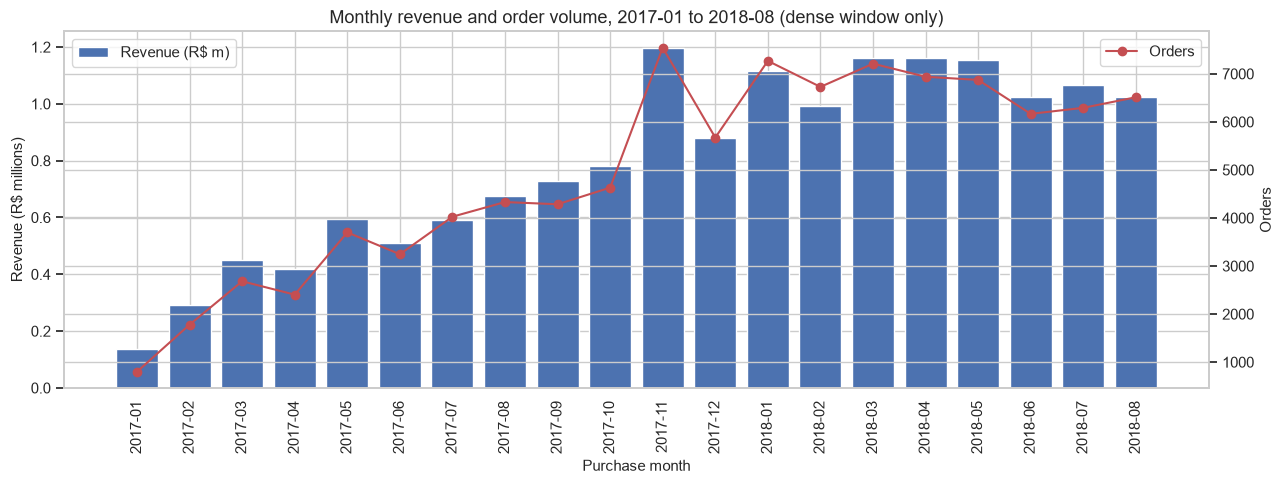

,orders,revenue_m,aov
month,,,
2017-01,800,0.140,173.110
2017-02,1780,0.290,163.990
2017-03,2682,0.450,167.730
2017-04,2404,0.420,173.790
2017-05,3700,0.590,160.250
2017-06,3245,0.510,157.560
2017-07,4026,0.590,147.140
2017-08,4331,0.670,155.710
2017-09,4285,0.730,169.840


In [5]:
base["month"] = base["order_purchase_timestamp"].dt.to_period("M")
monthly = base.groupby("month").agg(
    orders=("order_id", "size"),
    revenue=("payment_value", "sum"),
    aov=("payment_value", "mean"),
)
monthly["revenue_m"] = monthly["revenue"] / 1e6

dense = monthly.loc["2017-01":"2018-08"]

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar([str(p) for p in dense.index], dense["revenue_m"], color="#4c72b0", label="Revenue (R$ m)")
ax1.set_ylabel("Revenue (R$ millions)")
ax1.set_xlabel("Purchase month")
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()
ax2.plot([str(p) for p in dense.index], dense["orders"], color="#c44e52", marker="o", label="Orders")
ax2.set_ylabel("Orders")

ax1.set_title("Monthly revenue and order volume, 2017-01 to 2018-08 (dense window only)")
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

display(dense[["orders", "revenue_m", "aov"]].round(2))

**Reading it.** Revenue grows from **R$ 0.14M in January 2017** to a peak of **R$ 1.20M in
November 2017**, then plateaus around **R$ 1.0–1.16M per month** through 2018. The November 2017
spike (7,544 orders, +63% on October) is the Black Friday effect — the single largest month in the
dataset. Order volume and revenue move together, so growth is driven by **volume, not basket
size**: the average order value is essentially flat (R$ 147–174) across the whole window.

The 2016 head and the Sep–Oct 2018 tail are excluded from the chart because they hold 329 and 20
orders respectively — plotting them would show a fake collapse.

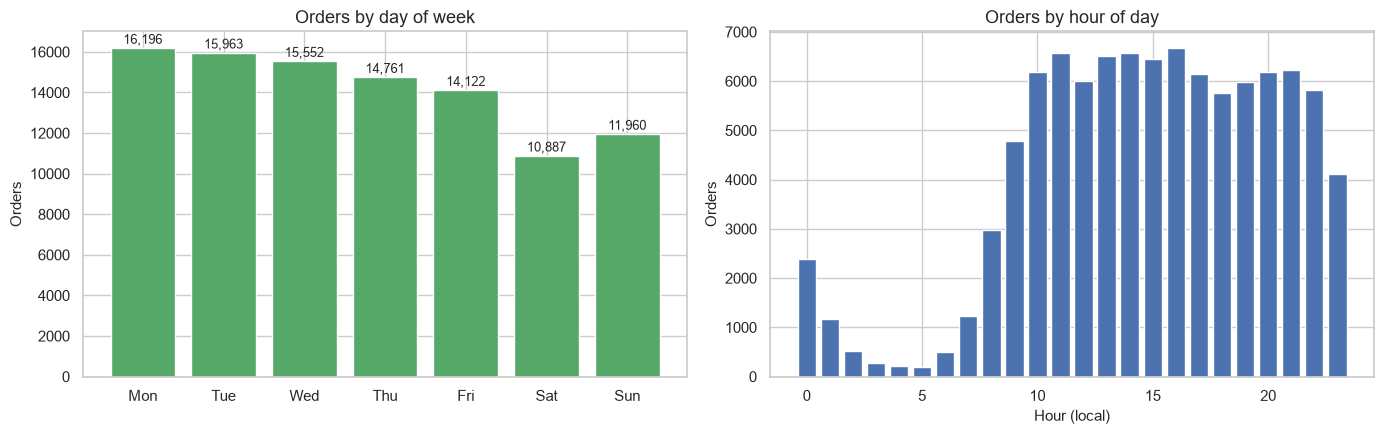

Busiest day  : Mon (16,196 orders)
Quietest day : Sat (10,887 orders)
Busiest hour : 16:00 (6,675 orders)
Share of orders placed 10:00-16:00: 45.22%


In [6]:
base["dow"] = base["order_purchase_timestamp"].dt.day_of_week
base["hour"] = base["order_purchase_timestamp"].dt.hour

dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow_counts = base["dow"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].bar(dow_names, dow_counts.values, color="#55a868")
axes[0].set_title("Orders by day of week")
axes[0].set_ylabel("Orders")
for i, v in enumerate(dow_counts.values):
    axes[0].text(i, v + 200, f"{v:,}", ha="center", fontsize=9)

hour_counts = base["hour"].value_counts().sort_index()
axes[1].bar(hour_counts.index, hour_counts.values, color="#4c72b0")
axes[1].set_title("Orders by hour of day")
axes[1].set_xlabel("Hour (local)")
axes[1].set_ylabel("Orders")

plt.tight_layout()
plt.show()

print(f"Busiest day  : {dow_names[dow_counts.idxmax()]} ({dow_counts.max():,} orders)")
print(f"Quietest day : {dow_names[dow_counts.idxmin()]} ({dow_counts.min():,} orders)")
print(f"Busiest hour : {hour_counts.idxmax():02d}:00 ({hour_counts.max():,} orders)")
print(f"Share of orders placed 10:00-16:00: {hour_counts.loc[10:16].sum() / hour_counts.sum() * 100:.2f}%")

**Reading it.** Purchasing is a **weekday, business-hours** activity. Monday is the busiest day
(16,196 orders) and Saturday the quietest (10,887) — a 33% gap. The hourly profile peaks at
**16:00** (6,675 orders) and **45.22% of all orders are placed between 10:00 and 16:00**. The
02:00–06:00 trough is near-empty.

Business implication: campaign sends and support staffing should follow the weekday
10:00–16:00 window; weekend volume does not justify the same coverage.

## 2. Category and seller performance

**Business questions.** Which categories generate the most revenue, how concentrated is that
revenue, and how dependent is the marketplace on a small number of sellers?

Category revenue is computed at **line-item level** (`order_items.price`), because an order can
span several categories. The 610 products with no catalogue category are bucketed as `unknown`
and their share is reported explicitly so the denominator stays honest.

In [7]:
category_revenue = (
    items_cat.groupby("category")
    .agg(revenue=("price", "sum"), items=("order_item_id", "size"), orders=("order_id", "nunique"))
    .sort_values("revenue", ascending=False)
)
category_revenue["revenue_share"] = category_revenue["revenue"] / category_revenue["revenue"].sum() * 100
category_revenue["cumulative_share"] = category_revenue["revenue_share"].cumsum()

print(f"Distinct categories with sales: {len(category_revenue)}")
print(f"Top 5 share : {category_revenue['revenue_share'].head(5).sum():.2f}%")
print(f"Top 10 share: {category_revenue['revenue_share'].head(10).sum():.2f}%")
print(f"Categories needed to reach 80% of revenue: {(category_revenue['cumulative_share'] < 80).sum() + 1} of {len(category_revenue)}")
print(f"'unknown' category revenue share: {category_revenue.loc['unknown', 'revenue_share']:.2f}%")
print()
display(category_revenue.head(15).round(2))

Distinct categories with sales: 74
Top 5 share : 39.74%
Top 10 share: 62.36%
Categories needed to reach 80% of revenue: 18 of 74
'unknown' category revenue share: 1.32%



,revenue,items,orders,revenue_share,cumulative_share
category,,,,,
health_beauty,"1,258,681.340",9670,8836,9.260,9.260
watches_gifts,"1,205,005.680",5991,5624,8.870,18.130
bed_bath_table,"1,036,988.680",11115,9417,7.630,25.760
sports_leisure,"988,048.970",8641,7720,7.270,33.030
computers_accessories,"911,954.320",7827,6689,6.710,39.740
furniture_decor,"729,762.490",8334,6449,5.370,45.100
cool_stuff,"635,290.850",3796,3632,4.670,49.780
housewares,"632,248.660",6964,5884,4.650,54.430
auto,"592,720.110",4235,3897,4.360,58.790


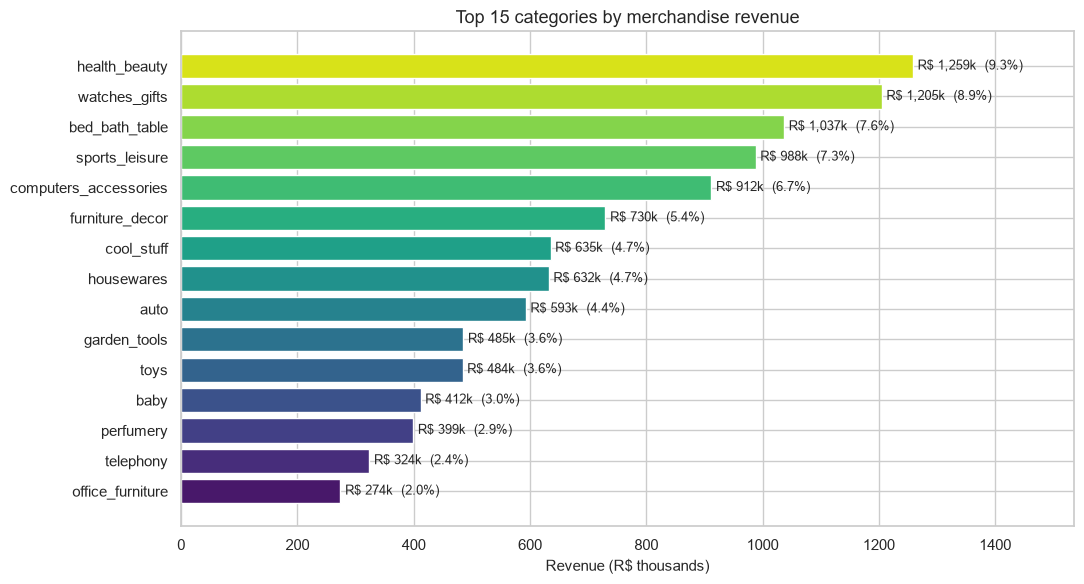

In [8]:
top15 = category_revenue.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(top15.index, top15["revenue"] / 1e3, color=sns.color_palette("viridis", len(top15)))
for bar, (_, row) in zip(bars, top15.iterrows(), strict=False):
    ax.text(
        bar.get_width() + 8,
        bar.get_y() + bar.get_height() / 2,
        f"R$ {row['revenue'] / 1e3:,.0f}k  ({row['revenue_share']:.1f}%)",
        va="center",
        fontsize=9,
    )
ax.set_xlabel("Revenue (R$ thousands)")
ax.set_title("Top 15 categories by merchandise revenue")
ax.set_xlim(0, top15["revenue"].max() / 1e3 * 1.22)
plt.tight_layout()
plt.show()

**Reading it.** Revenue is **moderately concentrated**: the top 5 of 74 categories hold **39.74%**
and the top 10 hold **62.36%**. It takes **18 categories to reach 80%** of revenue, so this is not
a winner-takes-all catalogue — there is a long, viable tail.

`health_beauty` leads (R$ 1.26M, 9.26%), followed by `watches_gifts` (8.87%) and `bed_bath_table`
(7.63%). Note the contrast between revenue and volume: `bed_bath_table` sells the most line items
(11,115) but ranks third on revenue, while `watches_gifts` sells only 5,991 items yet ranks second
— it is a high-ticket category. The `unknown` bucket is **1.32%** of revenue, small enough that
category conclusions are not distorted by the missing metadata.

Sellers with at least one sale: 3,095 of 3,095
Top 1% of sellers revenue share : 25.67%
Top 10% of sellers revenue share: 67.49%
Median seller revenue: R$ 821.48
Mean seller revenue  : R$ 4,391.48



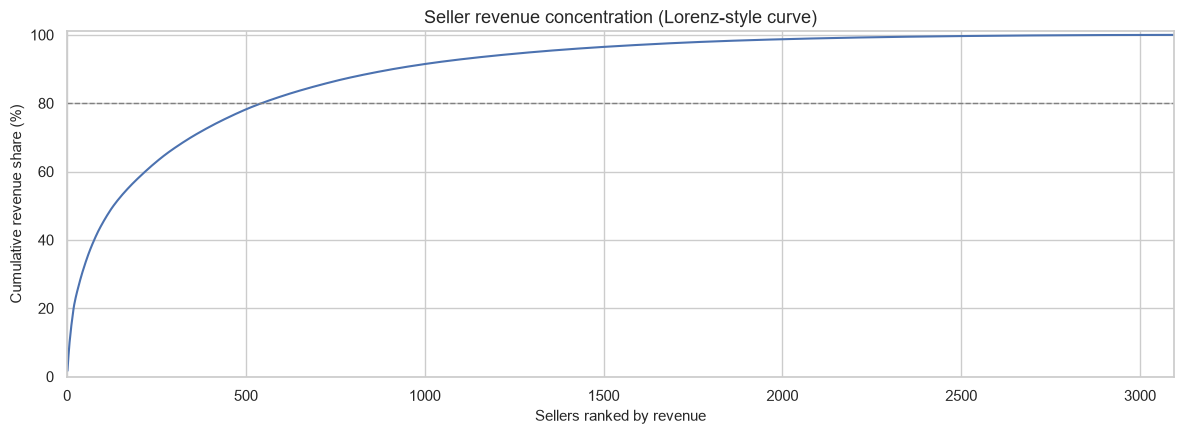

In [9]:
seller_revenue = items.groupby("seller_id")["price"].sum().sort_values(ascending=False)
n_sellers = len(seller_revenue)

top1 = seller_revenue.head(max(1, int(n_sellers * 0.01))).sum() / seller_revenue.sum() * 100
top10 = seller_revenue.head(max(1, int(n_sellers * 0.10))).sum() / seller_revenue.sum() * 100

print(f"Sellers with at least one sale: {n_sellers:,} of {len(sellers):,}")
print(f"Top 1% of sellers revenue share : {top1:.2f}%")
print(f"Top 10% of sellers revenue share: {top10:.2f}%")
print(f"Median seller revenue: R$ {seller_revenue.median():,.2f}")
print(f"Mean seller revenue  : R$ {seller_revenue.mean():,.2f}")
print()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(np.arange(1, n_sellers + 1), seller_revenue.cumsum().values / seller_revenue.sum() * 100, color="#4c72b0")
ax.axhline(80, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Sellers ranked by revenue")
ax.set_ylabel("Cumulative revenue share (%)")
ax.set_title("Seller revenue concentration (Lorenz-style curve)")
ax.set_xlim(0, n_sellers)
ax.set_ylim(0, 101)
plt.tight_layout()
plt.show()

**Reading it.** Seller concentration is **far sharper than category concentration**. The top 1% of
sellers (31 of 3,095) capture **25.67%** of revenue and the top 10% capture **67.49%**. The median
seller earns **R$ 821** over the entire two-year window against a mean of R$ 3,900 — most sellers
are marginal, and the marketplace's revenue depends on a small professional core.

Business implication: seller-level risk is real. Losing a handful of top-decile sellers would
remove two-thirds of revenue, so seller health and retention deserve the same attention as
customer acquisition.

## 3. Geography

**Business questions.** Where is demand concentrated, where are sellers located, and how much
commerce crosses state lines?

State is taken from `customers.customer_state` for demand and `sellers.seller_state` for supply.
Cross-state share is computed at **line-item level**, because a single order can be fulfilled by
sellers in different states.

In [10]:
geo = base.merge(customers[["customer_id", "customer_state", "customer_city"]], on="customer_id", how="left")
assert len(geo) == len(base)

state_stats = (
    geo.groupby("customer_state")
    .agg(orders=("order_id", "size"), revenue=("payment_value", "sum"))
    .sort_values("revenue", ascending=False)
)
state_stats["order_share"] = state_stats["orders"] / state_stats["orders"].sum() * 100
state_stats["revenue_share"] = state_stats["revenue"] / state_stats["revenue"].sum() * 100

print(f"States represented: {len(state_stats)}")
print(f"Top 3 states order share: {state_stats['order_share'].head(3).sum():.2f}%")
print()
display(state_stats.head(10).round(2))

States represented: 27
Top 3 states order share: 66.61%



,orders,revenue,order_share,revenue_share
customer_state,,,,
SP,41746,"5,998,226.960",41.980,37.470
RJ,12852,"2,144,379.690",12.920,13.390
MG,11635,"1,872,257.260",11.700,11.700
RS,5466,"890,898.540",5.500,5.570
PR,5045,"811,156.380",5.070,5.070
SC,3637,"623,086.430",3.660,3.890
BA,3380,"616,645.820",3.400,3.850
DF,2140,"355,141.080",2.150,2.220
GO,2020,"350,092.310",2.030,2.190


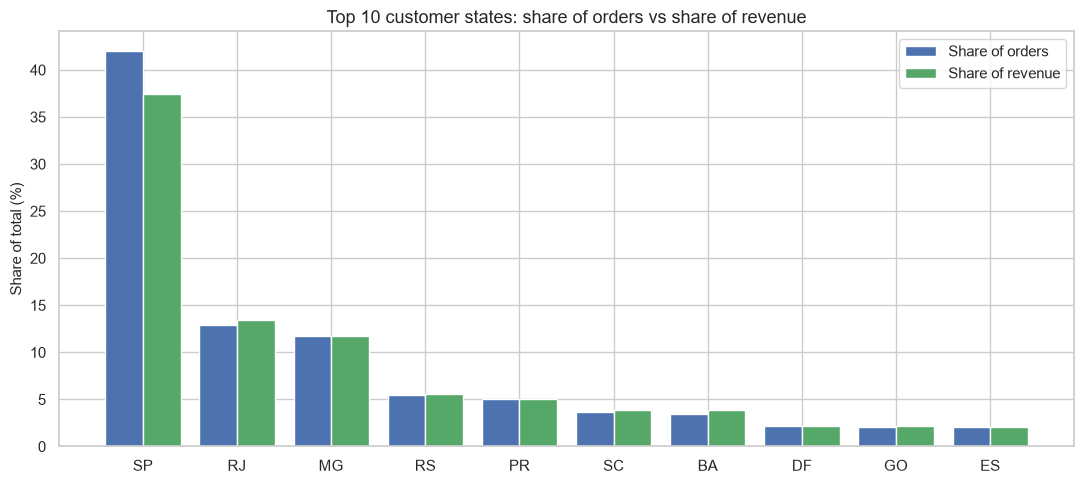

In [11]:
top10_states = state_stats.head(10)

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(top10_states))
width = 0.4
ax.bar(x - width / 2, top10_states["order_share"], width, label="Share of orders", color="#4c72b0")
ax.bar(x + width / 2, top10_states["revenue_share"], width, label="Share of revenue", color="#55a868")
ax.set_xticks(x)
ax.set_xticklabels(top10_states.index)
ax.set_ylabel("Share of total (%)")
ax.set_title("Top 10 customer states: share of orders vs share of revenue")
ax.legend()
plt.tight_layout()
plt.show()

**Reading it.** Demand is **heavily concentrated in the south-east**. São Paulo alone accounts for
**41,746 orders (41.98%)** and **37.47% of revenue**; the top three states (SP, RJ, MG) hold
**66.61%** of all orders. The order-share and revenue-share bars track closely, so the south-east
is not buying more expensive items — it is simply buying more.

The slight gap for SP (41.98% of orders vs 37.47% of revenue) means SP orders are **below-average
value**, consistent with a mature, price-competitive home market.

In [12]:
items_geo = (
    items.merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
    .merge(orders[["order_id", "customer_id"]], on="order_id", how="left")
    .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
)

cross_state_share = (items_geo["seller_state"] != items_geo["customer_state"]).mean() * 100

print(f"Line items analysed: {len(items_geo):,}")
print(f"Cross-state line items: {cross_state_share:.2f}%")
print()
print("Seller state distribution (top 8):")
print(sellers["seller_state"].value_counts().head(8).to_string())
print()
print(f"Sellers in SP: {int((sellers['seller_state'] == 'SP').sum()):,} of {len(sellers):,} "
      f"({(sellers['seller_state'] == 'SP').mean() * 100:.2f}%)")

Line items analysed: 112,650
Cross-state line items: 63.82%

Seller state distribution (top 8):
seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30

Sellers in SP: 1,849 of 3,095 (59.74%)


**Reading it.** Supply is even more concentrated than demand: **1,849 of 3,095 sellers (59.7%)** are
based in São Paulo, against 41.98% of orders. The consequence is that **63.82% of line items ship
across a state border** — the majority of Brazilian e-commerce in this dataset is long-distance.

This is the structural reason delivery performance varies so much by state (§4): a customer in
Alagoas is usually waiting on a parcel from São Paulo, roughly 2,000 km away.

## 4. Delivery performance

**Business questions.** How long does delivery take, how often does it miss the estimate, which
states and categories fail most, and has performance improved over time?

**Late definition (strict):** `order_delivered_customer_date > order_estimated_delivery_date`.
Eligible population = `order_status == 'delivered'` with both dates present — **96,470 orders**.

> **Sensitivity note.** `order_estimated_delivery_date` is date-only (100% at `00:00:00`), so a
> delivery on the estimated day counts as late. Reading the estimate as end-of-day would move the
> late rate from **8.11% to 6.77%** (1,292 orders reclassified). The strict definition is used
> throughout because it matches the documented ML target.

In [13]:
eligible = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

eligible["is_late"] = eligible["order_delivered_customer_date"] > eligible["order_estimated_delivery_date"]
eligible["delivery_days"] = (
    eligible["order_delivered_customer_date"] - eligible["order_purchase_timestamp"]
).dt.days
eligible["estimated_lead_days"] = (
    eligible["order_estimated_delivery_date"] - eligible["order_purchase_timestamp"]
).dt.days

n_eligible = len(eligible)
n_late = int(eligible["is_late"].sum())

print(f"Eligible orders : {n_eligible:,} of {len(orders):,} ({n_eligible / len(orders) * 100:.2f}%)")
print(f"Late orders     : {n_late:,} ({n_late / n_eligible * 100:.2f}%)")
print(f"On-time orders  : {n_eligible - n_late:,} ({(n_eligible - n_late) / n_eligible * 100:.2f}%)")
print()
print("Actual delivery duration (days):")
print(eligible["delivery_days"].describe().round(2).to_string())
print()
print("Estimated lead time (days):")
print(eligible["estimated_lead_days"].describe().round(2).to_string())
print()
print(f"Orders delivered before the estimate: {(eligible['delivery_days'] < eligible['estimated_lead_days']).mean() * 100:.2f}%")

Eligible orders : 96,470 of 99,441 (97.01%)
Late orders     : 7,826 (8.11%)
On-time orders  : 88,644 (91.89%)

Actual delivery duration (days):
count   96,470.000
mean        12.090
std          9.550
min          0.000
25%          6.000
50%         10.000
75%         15.000
max        209.000

Estimated lead time (days):
count   96,470.000
mean        23.370
std          8.760
min          2.000
25%         18.000
50%         23.000
75%         28.000
max        155.000

Orders delivered before the estimate: 91.00%


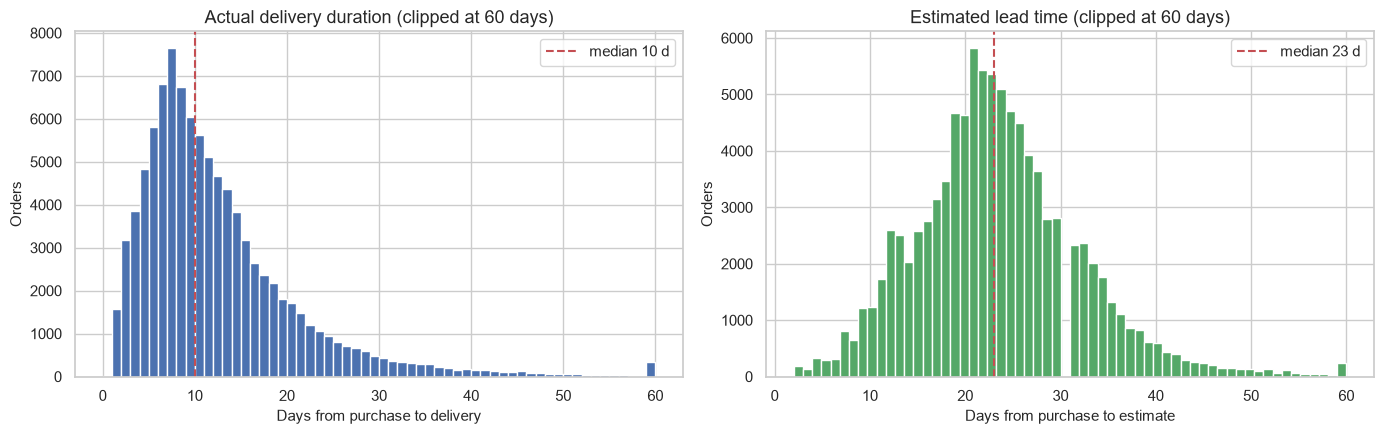

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(eligible["delivery_days"].clip(upper=60), bins=60, color="#4c72b0")
axes[0].axvline(eligible["delivery_days"].median(), color="#c44e52", linestyle="--",
                label=f"median {eligible['delivery_days'].median():.0f} d")
axes[0].set_title("Actual delivery duration (clipped at 60 days)")
axes[0].set_xlabel("Days from purchase to delivery")
axes[0].set_ylabel("Orders")
axes[0].legend()

axes[1].hist(eligible["estimated_lead_days"].clip(upper=60), bins=60, color="#55a868")
axes[1].axvline(eligible["estimated_lead_days"].median(), color="#c44e52", linestyle="--",
                label=f"median {eligible['estimated_lead_days'].median():.0f} d")
axes[1].set_title("Estimated lead time (clipped at 60 days)")
axes[1].set_xlabel("Days from purchase to estimate")
axes[1].set_ylabel("Orders")
axes[1].legend()

plt.tight_layout()
plt.show()

**Reading it.** Delivery is **fast relative to the promise**. The median actual duration is
**10 days** against a median estimated lead time of **23 days**, and **91.00% of orders arrive
before the estimate**. The estimate is deliberately conservative — it is a buffer, not a forecast.

That is why the late rate is only 8.11% despite a long tail: the mean duration is 12.09 days but
the 90th percentile is 23 days and the maximum is **209 days**. The tail is where the failures
live, and it is thin enough that the median tells a misleadingly comfortable story.

In [15]:
eligible_geo = eligible.merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")

by_state = (
    eligible_geo.groupby("customer_state")
    .agg(orders=("order_id", "size"), late_rate=("is_late", "mean"), median_days=("delivery_days", "median"))
    .query("orders >= 200")
    .sort_values("late_rate", ascending=False)
)
by_state["late_pct"] = by_state["late_rate"] * 100

print(f"States with at least 200 eligible orders: {len(by_state)}")
print()
print("Worst 8 states by late rate:")
display(by_state.head(8)[["orders", "late_pct", "median_days"]].round(2))
print("Best 5 states by late rate:")
display(by_state.tail(5)[["orders", "late_pct", "median_days"]].round(2))

States with at least 200 eligible orders: 23

Worst 8 states by late rate:


,orders,late_pct,median_days
customer_state,,,
AL,397,23.930,22.000
MA,717,19.670,19.000
PI,476,15.970,16.000
CE,1279,15.320,18.000
SE,335,15.220,18.000
BA,3256,14.040,16.000
RJ,12350,13.470,12.000
TO,274,12.770,15.000


Best 5 states by late rate:


,orders,late_pct,median_days
customer_state,,,
MT,886,6.770,16.000
SP,40494,5.890,7.000
MG,11354,5.610,10.000
PR,4923,5.000,10.000
RO,243,2.880,17.000


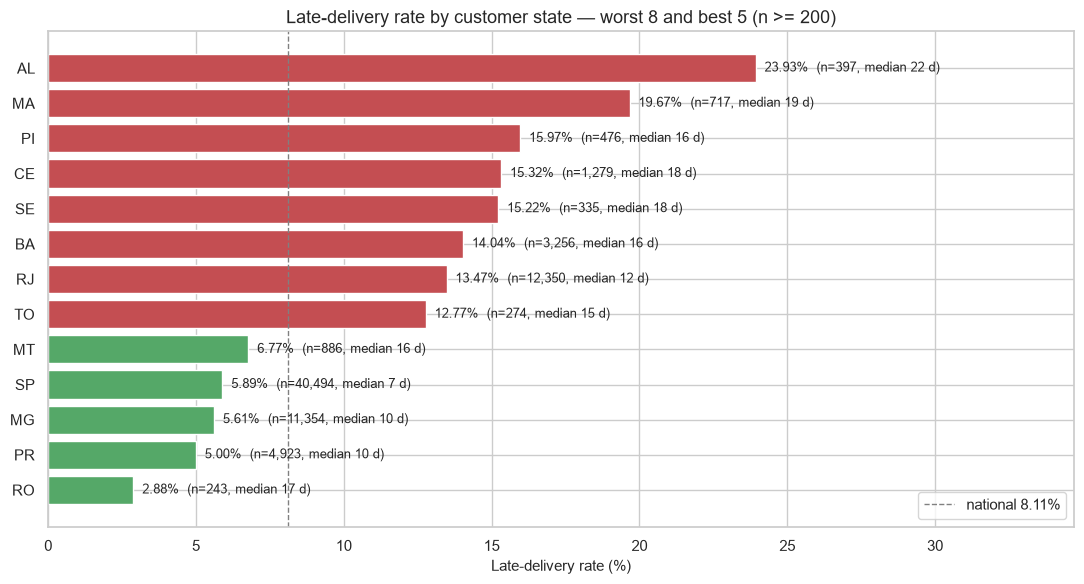

In [16]:
plot_states = pd.concat([by_state.head(8), by_state.tail(5)]).sort_values("late_pct")

fig, ax = plt.subplots(figsize=(11, 6))
colors = ["#c44e52" if v > 8.11 else "#55a868" for v in plot_states["late_pct"]]
bars = ax.barh(plot_states.index, plot_states["late_pct"], color=colors)
for bar, (_, row) in zip(bars, plot_states.iterrows(), strict=False):
    ax.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{row['late_pct']:.2f}%  (n={int(row['orders']):,}, median {row['median_days']:.0f} d)",
        va="center",
        fontsize=9,
    )
ax.axvline(8.11, color="grey", linestyle="--", linewidth=1, label="national 8.11%")
ax.set_xlabel("Late-delivery rate (%)")
ax.set_title("Late-delivery rate by customer state — worst 8 and best 5 (n >= 200)")
ax.set_xlim(0, plot_states["late_pct"].max() * 1.45)
ax.legend()
plt.tight_layout()
plt.show()

**Reading it.** The geographic spread is **enormous — a factor of eight**. Alagoas is worst at
**23.93% late** (397 orders, median 22 days), followed by Maranhão (19.67%), Piauí (15.97%) and
Ceará (15.32%). Rondônia is best at **2.88%**, with Paraná (5.00%), Minas Gerais (5.61%) and São
Paulo (5.89%) close behind.

The pattern is not random: every high-late state is in the **north-east or north**, far from the
São Paulo seller base, and every low-late state is in the **south-east or south**. Median delivery
time tracks it directly — 22 days in Alagoas vs 7 days in São Paulo. This is the §3 cross-state
finding showing up as a delivery penalty.

In [17]:
eligible_cat = (
    eligible.merge(items[["order_id", "product_id"]].drop_duplicates("order_id"), on="order_id", how="left")
    .merge(products_cat[["product_id", "category"]], on="product_id", how="left")
)
eligible_cat["category"] = eligible_cat["category"].fillna("unknown")

by_category = (
    eligible_cat.groupby("category")
    .agg(orders=("order_id", "size"), late_rate=("is_late", "mean"), median_days=("delivery_days", "median"))
    .query("orders >= 300")
    .sort_values("late_rate", ascending=False)
)
by_category["late_pct"] = by_category["late_rate"] * 100

print(f"Categories with at least 300 eligible orders: {len(by_category)}")
print()
print("Worst 8 categories by late rate:")
display(by_category.head(8)[["orders", "late_pct", "median_days"]].round(2))
print("Best 5 categories by late rate:")
display(by_category.tail(5)[["orders", "late_pct", "median_days"]].round(2))

Categories with at least 300 eligible orders: 32

Worst 8 categories by late rate:


,orders,late_pct,median_days
category,,,
audio,344,13.080,10.000
home_confort,370,10.270,11.000
food,435,10.110,7.000
electronics,2507,9.850,11.000
baby,2763,9.340,10.000
office_furniture,1246,9.230,18.000
construction_tools_construction,728,9.200,8.000
health_beauty,8608,8.990,9.000


Best 5 categories by late rate:


,orders,late_pct,median_days
category,,,
home_appliances,747,6.690,9.000
fashion_bags_accessories,1810,6.630,9.000
pet_shop,1682,6.300,9.000
small_appliances,606,6.270,8.500
luggage_accessories,1008,5.460,9.000


**Reading it.** Category matters far less than geography. The worst category, `audio`, is
**13.08% late** — well below the worst state's 23.93% — and the spread across categories is
roughly 13% down to 5%. `home_confort` (10.27%), `food` (10.11%) and `electronics` (9.85%) follow.

Notably `office_furniture` is 9.23% late with a **median of 18 days**, nearly double the national
median of 10 — bulky furniture is slow even when it is not late. Category is a secondary driver;
destination is the primary one.

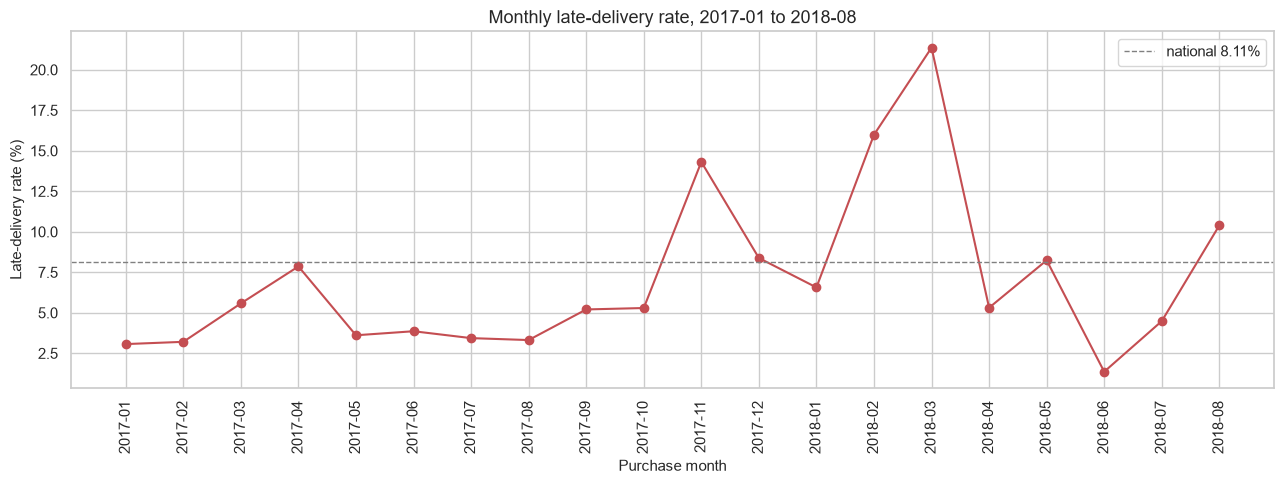

,orders,late_pct
month,,
2017-01,750,3.070
2017-02,1653,3.210
2017-03,2546,5.580
2017-04,2303,7.860
2017-05,3545,3.610
2017-06,3135,3.860
2017-07,3872,3.430
2017-08,4193,3.320
2017-09,4150,5.200


In [18]:
eligible["month"] = eligible["order_purchase_timestamp"].dt.to_period("M")
monthly_late = eligible.groupby("month").agg(orders=("order_id", "size"), late_rate=("is_late", "mean"))
monthly_late["late_pct"] = monthly_late["late_rate"] * 100
dense_late = monthly_late.loc["2017-01":"2018-08"]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot([str(p) for p in dense_late.index], dense_late["late_pct"], marker="o", color="#c44e52")
ax.axhline(8.11, color="grey", linestyle="--", linewidth=1, label="national 8.11%")
ax.set_ylabel("Late-delivery rate (%)")
ax.set_xlabel("Purchase month")
ax.set_title("Monthly late-delivery rate, 2017-01 to 2018-08")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

display(dense_late[["orders", "late_pct"]].round(2))

**Reading it.** The late rate is **volatile and shows two severe spikes**: **14.31% in November
2017** and **21.36% in March 2018**, against a baseline of roughly 3–5%. November 2017 is the
Black Friday month — volume rose 63% and the logistics network visibly failed to absorb it. March
2018 is harder to explain from volume alone (7,003 orders, in line with neighbouring months), so
it points to a capacity or carrier event rather than demand.

The **1.36% in June 2018** is the opposite extreme and is suspicious in the other direction — a
rate that low suggests the estimate was set unusually generously that month rather than that
delivery suddenly improved. Both anomalies are flagged for investigation rather than explained
away.

Business implication: the late rate is **not a stable process**. Any model or SLA built on a
single-period average will be wrong in the peak months, which are exactly the months that matter.

## 5. Customer experience

**Business questions.** What does satisfaction look like, how strongly does it track delivery, and
how many customers come back?

**Score only.** All 99,224 reviews are analysed by `review_score`. Text is deliberately excluded:
only **40,977 reviews (41.3%)** contain a comment, and that subpopulation is heavily biased —
mean score **3.67 with text vs 4.38 without**, with 1-star reviews at 21.34% of commenters vs
4.60% of silent reviewers. Any text-based conclusion would describe complainers, not customers.

Reviews are deduplicated to the latest review per order before joining (547 orders have more than
one review).

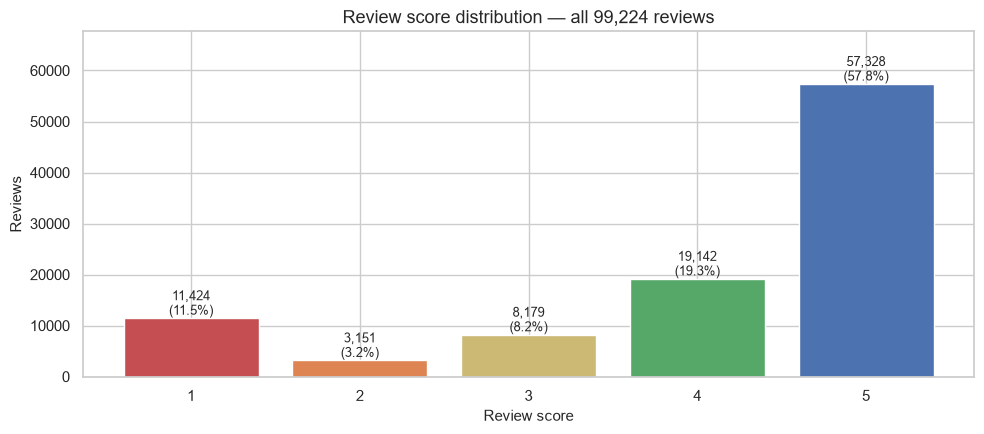

Mean score  : 4.086
Median score: 5
5-star share: 57.78%
1-star share: 11.51%
Share scoring 4 or 5: 77.07%


In [19]:
score_counts = reviews["review_score"].value_counts().sort_index()
score_pct = score_counts / score_counts.sum() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(score_counts.index.astype(str), score_counts.values,
              color=["#c44e52", "#dd8452", "#ccb974", "#55a868", "#4c72b0"])
for bar, (score, count) in zip(bars, score_counts.items(), strict=False):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 700,
            f"{count:,}\n({score_pct[score]:.1f}%)", ha="center", fontsize=9)
ax.set_xlabel("Review score")
ax.set_ylabel("Reviews")
ax.set_title("Review score distribution — all 99,224 reviews")
ax.set_ylim(0, score_counts.max() * 1.18)
plt.tight_layout()
plt.show()

print(f"Mean score  : {reviews['review_score'].mean():.3f}")
print(f"Median score: {reviews['review_score'].median():.0f}")
print(f"5-star share: {score_pct[5]:.2f}%")
print(f"1-star share: {score_pct[1]:.2f}%")
print(f"Share scoring 4 or 5: {score_pct.loc[[4, 5]].sum():.2f}%")

**Reading it.** Satisfaction is **strongly bimodal**. 5-star reviews are **57.78%** and 1-star
reviews **11.51%**, while the middle scores are comparatively rare — 3-star is only 8.24%. The mean
of **4.086** hides this: customers either love the order or hate it, and there is very little
lukewarm feedback.

That shape is a warning for any satisfaction metric. A mean of 4.09 sounds healthy, but 11.5% of
customers are actively hostile, and the bimodality suggests the driver is a binary experience
(delivered as promised, or not) rather than a gradient of quality.

In [20]:
eligible_reviews = eligible.merge(reviews_dedup, on="order_id", how="left")
print(f"Eligible orders with a review: {int(eligible_reviews['review_score'].notna().sum()):,} of {len(eligible_reviews):,}")

by_late = eligible_reviews.groupby("is_late")["review_score"].agg(["count", "mean", "median"])
by_late.index = ["on time", "late"]
display(by_late.round(3))

dist = pd.crosstab(eligible_reviews["review_score"], eligible_reviews["is_late"], normalize="columns") * 100
dist.columns = ["on time", "late"]
print()
print("Score distribution by delivery outcome (% of column):")
display(dist.round(2))

late_1star = (eligible_reviews.loc[eligible_reviews["is_late"], "review_score"] == 1).mean() * 100
ontime_1star = (eligible_reviews.loc[~eligible_reviews["is_late"], "review_score"] == 1).mean() * 100
print(f"1-star share when late    : {late_1star:.2f}%")
print(f"1-star share when on time : {ontime_1star:.2f}%")

Eligible orders with a review: 95,824 of 96,470


,count,mean,median
on time,88163,4.294,5.000
late,7661,2.565,2.000



Score distribution by delivery outcome (% of column):


,on time,late
review_score,,
1.000,6.590,46.210
2.000,2.630,7.860
3.000,7.990,11.380
4.000,20.350,12.320
5.000,62.440,22.230


1-star share when late    : 45.23%
1-star share when on time : 6.56%


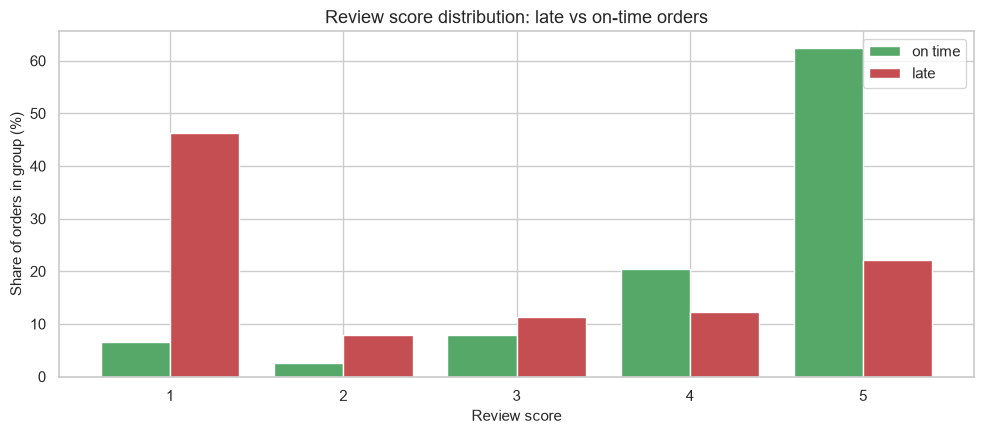

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(1, 6)
width = 0.4
ontime = dist["on time"].reindex([1, 2, 3, 4, 5]).values
late = dist["late"].reindex([1, 2, 3, 4, 5]).values
ax.bar(x - width / 2, ontime, width, label="on time", color="#55a868")
ax.bar(x + width / 2, late, width, label="late", color="#c44e52")
ax.set_xticks(x)
ax.set_xlabel("Review score")
ax.set_ylabel("Share of orders in group (%)")
ax.set_title("Review score distribution: late vs on-time orders")
ax.legend()
plt.tight_layout()
plt.show()

**Reading it.** This is the strongest relationship in the notebook. Mean score is **4.294 for
on-time orders vs 2.565 for late ones** — a **1.73-point gap** on a 5-point scale. The
distributions barely overlap: **62.44% of on-time orders get 5 stars**, while **46.21% of late
orders get 1 star**.

Put differently, a late order is **6.9× more likely to receive a 1-star review** (45.23% vs
6.56%). Delivery failure is not one factor among many in customer satisfaction — it is close to
the whole story.

,count,mean
duration_bucket,,
0-3 d,8565,4.459
4-7 d,24974,4.391
8-14 d,36190,4.289
15-21 d,15264,4.101
22-30 d,6824,3.494
31+ d,4007,2.174


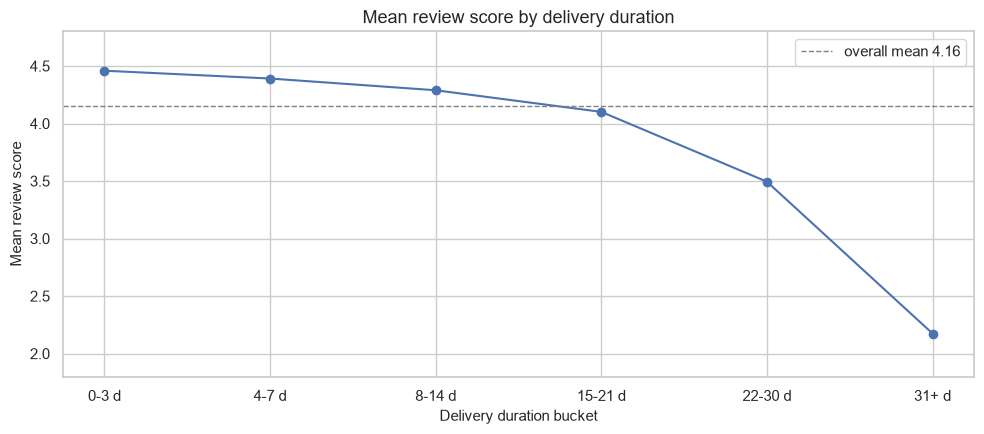

In [22]:
eligible_reviews["duration_bucket"] = pd.cut(
    eligible_reviews["delivery_days"],
    bins=[-1, 3, 7, 14, 21, 30, 1000],
    labels=["0-3 d", "4-7 d", "8-14 d", "15-21 d", "22-30 d", "31+ d"],
)

by_duration = (
    eligible_reviews.groupby("duration_bucket", observed=True)["review_score"]
    .agg(["count", "mean"])
    .round(3)
)
display(by_duration)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(by_duration.index.astype(str), by_duration["mean"], marker="o", color="#4c72b0")
ax.axhline(eligible_reviews["review_score"].mean(), color="grey", linestyle="--", linewidth=1,
           label=f"overall mean {eligible_reviews['review_score'].mean():.2f}")
ax.set_xlabel("Delivery duration bucket")
ax.set_ylabel("Mean review score")
ax.set_title("Mean review score by delivery duration")
ax.set_ylim(1.8, 4.8)
ax.legend()
plt.tight_layout()
plt.show()

**Reading it.** Satisfaction is **flat until about two weeks, then falls off a cliff**. Orders
delivered in 0–3 days average **4.459** and 8–14 days still average **4.289** — a difference of
only 0.17 points. But 22–30 days drops to **3.494** and 31+ days collapses to **2.174**.

The threshold matters commercially: the first two weeks are effectively free from a satisfaction
standpoint, so the operational target should be "under 15 days", not "as fast as possible". Beyond
three weeks, satisfaction is unrecoverable regardless of anything else about the order.

In [23]:
orders_per_person = customers["customer_unique_id"].value_counts()
n_people = customers["customer_unique_id"].nunique()
n_repeat = int((orders_per_person > 1).sum())

print(f"Distinct people (customer_unique_id): {n_people:,}")
print(f"People with more than one order     : {n_repeat:,} ({n_repeat / n_people * 100:.2f}%)")
print(f"People with exactly one order       : {n_people - n_repeat:,} ({(n_people - n_repeat) / n_people * 100:.2f}%)")
print(f"Maximum orders by one person        : {int(orders_per_person.max())}")
print()
print("Orders per person (distribution):")
print(orders_per_person.value_counts().sort_index().head(6).to_string())

Distinct people (customer_unique_id): 96,096
People with more than one order     : 2,997 (3.12%)
People with exactly one order       : 93,099 (96.88%)
Maximum orders by one person        : 17

Orders per person (distribution):
count
1    93099
2     2745
3      203
4       30
5        8
6        6


**Reading it.** Repeat purchasing is **almost absent**: only **2,997 of 96,096 people (3.12%)**
ever place a second order, and the maximum is 17 orders. **96.88% of customers buy exactly once.**

This reframes the whole business. With a 3.12% repeat rate, the marketplace is effectively
**acquisition-only** — there is no retention engine to protect. It also means customer-lifetime
value analysis is not meaningful here: the "lifetime" is one order for almost everyone, so
revenue per customer and revenue per order are nearly the same number.

It also explains why delivery performance matters so much: with no repeat business, a bad first
experience has no second chance to be corrected, and the 1-star review is the last word.

## Business findings

1. **Revenue grew 8.6× in 20 months, driven entirely by order volume, not basket size.**
   Monthly revenue rose from R$ 0.14M (Jan 2017) to R$ 1.20M (Nov 2017) and plateaued at
   R$ 1.0–1.16M through 2018. Average order value stayed flat at R$ 147–174 across the whole
   window, so growth came from more orders (800 → ~6,500 per month), not from customers spending
   more. *Implication:* growth levers are acquisition and seller supply, not upselling.

2. **Delivery failure is the dominant driver of customer satisfaction — a 1.73-point gap.**
   Mean review score is **4.294 for on-time orders vs 2.565 for late ones** (95,824 reviewed
   eligible orders). 62.44% of on-time orders get 5 stars; 46.21% of late orders get 1 star. A
   late order is **6.9× more likely** to be rated 1 star (45.23% vs 6.56%). *Implication:*
   delivery reliability is the highest-leverage customer-experience investment available.

3. **Late delivery is a geographic problem, not a category problem — an eightfold spread.**
   Alagoas is **23.93% late** (397 orders, median 22 days) against Rondônia's **2.88%** and São
   Paulo's **5.89%** (40,494 orders, median 7 days). Every high-late state is in the north or
   north-east; every low-late state is in the south-east or south. Category spread is much
   narrower (13.08% worst vs ~5% best). *Implication:* route and carrier investment should target
   the north-east, not specific product lines.

4. **The marketplace is acquisition-only: 96.88% of customers never return.**
   Only **2,997 of 96,096 people (3.12%)** place more than one order, with a maximum of 17.
   *Implication:* there is no retention base to defend, so every order is a first impression and
   customer-lifetime-value analysis is not meaningful at this repeat rate.

5. **Revenue depends on a small seller core: the top 10% of sellers hold 67.49% of revenue.**
   Of 3,095 sellers, the top 1% (31 sellers) capture **25.67%** and the top 10% capture
   **67.49%**, while the median seller earns **R$ 821** over two years. Category concentration is
   milder — the top 5 of 74 categories hold 39.74%, and 18 categories are needed to reach 80%.
   *Implication:* seller concentration is a material business risk; losing a handful of top-decile
   sellers would remove two-thirds of revenue.

6. **The late rate is volatile, with two severe spikes that a single average would hide.**
   The national rate is **8.11% of 96,470 eligible orders**, but monthly it swings from **1.36%
   (Jun 2018)** to **21.36% (Mar 2018)**, with **14.31% in Nov 2017** — the Black Friday month,
   when volume rose 63% and the network visibly failed to absorb it. *Implication:* any SLA or
   model built on a period average will be badly wrong in peak months, which are the months that
   matter most.

7. **Freight is 16.57% of merchandise value, and 63.82% of items ship across state lines.**
   Merchandise revenue is R$ 13.59M against R$ 2.25M of freight, and 59.7% of sellers are based in
   São Paulo while only 41.98% of orders originate there. *Implication:* logistics cost and
   distance are structural features of this marketplace, not edge cases — which is why they belong
   in the delivery-delay model.

## Handover to Phase 3

- The order-level base table built in §0.1 (99,441 rows, asserted) is the shape Phase 3 must
  reproduce in `src/preprocessing/`.
- Review deduplication (latest `review_answer_timestamp`) and the `unknown` category bucket are
  validated here and should become Pandera-checked steps.
- The **March 2018 late-rate spike (21.36%)** and the **June 2018 trough (1.36%)** are unexplained
  and should be investigated before they are used as model signal.
- The strict late definition is confirmed as the working target; the end-of-day sensitivity
  (8.11% → 6.77%) remains an open decision for Phase 6.